# 2. A retailer that finances its stock from cash

A retailer sells three lines over a year of 52 weeks: a staple with a thin margin and steady demand, a seasonal line
with a high margin whose demand peaks before the year end, and a fashion line with a high margin and volatile demand.
It pays suppliers when it orders, and the seasonal goods take eight weeks to arrive, so the seasonal stock has to be
bought before the season shows how strong it is. A fixed overhead is due every week. The firm starts the year with
2,500 in cash (hundreds of dollars) and has no credit line: the first week that ends with negative cash is
insolvency.

Buying more seasonal stock earns more on average and makes insolvency more likely in a weak year. A price of failure
risk decides that trade-off. This notebook shows, on this problem:

1. how to state the requirement and the cost of failure;
2. that a structured rule already in use is a candidate, and a strong one;
3. what the cost of insolvency does to learned policies;
4. that the deployed policy's dispersion can carry much of its risk;
5. how to start a learner from the rule, and what anchoring to it does;
6. why an adaptive multiplier for a tolerance needs care;
7. how to validate the candidates and report.

The learned policies come from the campaign in `campaigns/` (PPO, three seeds per configuration); this notebook
loads them and evaluates them again. It runs in a few minutes with numpy, scipy, matplotlib and Stable-Baselines3.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve() / "campaigns"))
from records import Campaign
from bpg import Requirement, Stage, evaluate, interpret, plan
from bpg.problems.inventory import Retailer, InventoryCore, make_inventory_env, BaseStockRule

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
retailer = Retailer()
spec = retailer.spec()
camp = Campaign("retailer")

## 1. The problem as a budget

The budget is the starting cash. A week's resource use is its net cash outflow (orders, holding costs and overhead
minus revenue), which is negative in good weeks; the wrapper's `RunningMaxCost` charges only increases of the
cumulative outflow, so the budget runs out exactly in the first week with negative cash. The utility is the week's
profit. Below are thirty simulated years of cash under the retailer's current rule; years that end in insolvency
are drawn in red.

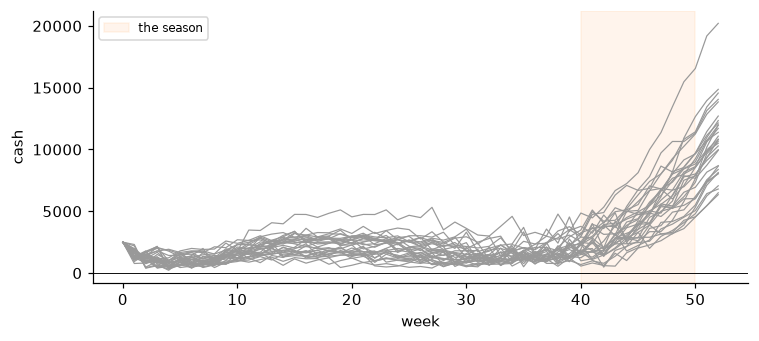

In [2]:
rule = BaseStockRule(retailer, cover=2.0, reserve=300.0)    # order up to the lead-time demand plus two weeks; keep 300 in cash


def cash_path(policy, seed):
    core = InventoryCore(retailer)
    obs, _ = core.reset(seed=seed)
    cash = [retailer.cash]
    for week in range(retailer.weeks):
        obs, profit, _, end, info = core.step(policy(np.append(obs, 1.0)))
        cash.append(info["cash"])
        if info["cash"] < 0 or end:
            break
    return np.array(cash)


fig, ax = plt.subplots(figsize=(7, 3.2))
for s in range(30):
    c = cash_path(rule.deterministic, 1000 + s)
    ax.plot(c, color="C3" if c.min() < 0 else "0.6", lw=0.8)
ax.axhline(0, color="k", lw=0.6)
ax.axvspan(retailer.peak - 6, retailer.season_end, color="C1", alpha=0.08, label="the season")
ax.set_xlabel("week"); ax.set_ylabel("cash"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

Cash falls through the first half of the year, when the seasonal and fashion lines sell little and the overhead is
still due, and rises with the season. A weak year deepens the trough; that is when the firm can run out.

## 2. The requirement and the cost of failure

The firm's lender asks that insolvency within the year have probability at most 2%, shown at 95% confidence. The
owners also put a cost on insolvency: losing the business is worth about 5,000, most of a year's profit. With a
known cost, the objective is the economic one: profit minus 5,000 times the probability of insolvency. We charge
it once, at the week of insolvency, with a flat penalty. Eight candidates will be inspected before one is deployed,
so the validation error is shared among eight.

In [3]:
req = Requirement(T=retailer.weeks - 1, alpha=0.02, zeta=0.05, family=8)
F = 5000.0
stage = Stage(m=0.0, penalty="multiplier", multiplier=F, clip_utility=False)
p = plan(spec, req, stage=stage, failure_permissible_at_deployment=True, violations_during_training_matter=False,
         loss_grows_with_excess_consumption=False, model_known_and_small=False, episode_earnings=6500.0)
print(p.explain())

Requirement: p_T <= 0.02 at T = 51 (52 actions), validation error 0.05 shared by 8 statements; kind = finite.
When another method is the better choice [paper, 'Which formulation to prefer']:
  [does not apply] no failure is permissible and a controlled-invariant set is known: an almost-sure method (an infinite failure penalty, a control-barrier safety layer, or a method that learns which actions keep probability-one budget constraints). Reason: a finite price prices failure risk and does not prohibit failure; a class of full-support policies can have a positive risk floor.
  [not stated] a prescribed level is attainable with slack and the multiplier's step can be tuned: an adaptive multiplier (a Lagrangian chance-constrained policy gradient). Reason: a fixed price leaves the attained risk to the optimizer, and unused risk costs utility; with too large a step the multiplier increases without bound when the initial policy fails often, as in the fuel-tank study.
  [does not apply] violati

None of the cases for another method applies: failures are allowed in simulation, the requirement is a probability,
and the simulator is not small enough to solve exactly. The plan also sizes the validation test.

## 3. The rule in use is a candidate

The retailer's rule orders up to the expected demand over the lead time plus a cover of a few weeks, and never
spends cash below a reserve. Any rule is a policy, and the toolbox evaluates and validates it like a trained network.
Varying the cover of the seasonal and fashion lines and the cash reserve shows the trade-off within the rule family.

In [4]:
def assess(policy, n=2000, seed=11, st=stage):
    return evaluate(lambda: make_inventory_env(st, retailer), policy, n, spec=spec, stage=st, T=req.T, seed=seed)


rules = {"in use (cover 2, reserve 300)": BaseStockRule(retailer, 2.0, 300.0),
         "no cash reserve": BaseStockRule(retailer, 2.0, 0.0),
         "more seasonal stock": BaseStockRule(retailer, (2, 4, 4), 300.0),
         "much more seasonal stock": BaseStockRule(retailer, (2, 6, 5), 0.0),
         "less seasonal stock": BaseStockRule(retailer, (2, 1, 1), 300.0)}
rule_ev = {name: assess(r.deterministic) for name, r in rules.items()}
for name, e in rule_ev.items():
    print(f"{name:32s} insolvency {e.p_T:6.2%}   profit {e.U:7.0f}")

in use (cover 2, reserve 300)    insolvency  0.30%   profit    6621
no cash reserve                  insolvency  2.20%   profit    6542
more seasonal stock              insolvency  0.75%   profit    6700
much more seasonal stock         insolvency 12.35%   profit    6033
less seasonal stock              insolvency  0.20%   profit    6221


The cash reserve lowers the risk and does not cost profit, because an insolvent year forfeits the rest of its
profit. More seasonal stock raises the risk faster than the profit.

## 4. Learned policies at several costs of failure

The campaign trained PPO from scratch (10 million steps, about 190,000 simulated years per run, three seeds) with
insolvency costing 0, 2,000, 5,000 and 20,000. The table shows the risk and profit of the trained stochastic
policies on 2,000 fresh years each: the mean over seeds and the range across them. With 2,000 years, a risk of 1% is
measured to within about half a percentage point.

configuration    seeds        failure (min-max)          utility (min-max)
unpriced             3     1.900% (1.60%-2.10%)           7486 (7242-7625)
lump-2000            3     1.483% (0.25%-2.20%)           7553 (7392-7708)
lump-5000            3     1.700% (1.15%-2.80%)           7512 (7313-7677)
lump-20000           3     0.617% (0.25%-0.85%)           7078 (6943-7232)


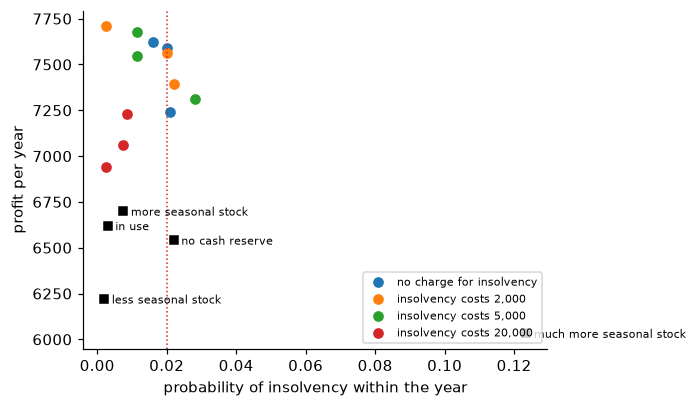

In [5]:
costs = ["unpriced", "lump-2000", "lump-5000", "lump-20000"]
print(Campaign.show(camp.table(costs)))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
for i, cfg in enumerate(costs):
    for r in camp.records(cfg):
        ax.plot(np.mean(r["evaluation"]["failed"]), np.mean(r["evaluation"]["U"]), "o", color=f"C{i}",
                label=r["note"] if r["seed"] == 1 else None)
for name, e in rule_ev.items():
    ax.plot(e.p_T, e.U, "s", color="k", ms=5)
    ax.annotate(name.split(" (")[0], (e.p_T, e.U), textcoords="offset points", xytext=(5, -3), fontsize=7)
ax.axvline(req.alpha, color="C3", ls=":", lw=1)
ax.set_xlabel("probability of insolvency within the year"); ax.set_ylabel("profit per year")
ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

The learned policies earn more than the rule in use. Without a cost of insolvency they already avoid it in most
years, since an insolvent year forfeits the rest of its profit; costs of 2,000 and 5,000 change little, less than
the differences between seeds. A cost of 20,000, about three years of profit, moves the policies close to the rule's
level of risk, and they still earn more than the rule. The price chooses a point on the trade-off between profit
and risk, and it matters when it is large against what a failure already costs.

The rule is a candidate all the same, and a strong one: it is far simpler, and its risk is the lowest measured. The
toolbox does not assume that a learned policy is better; it validates both.

Training long enough matters. The learning curves below were still rising after a few million steps: compared at
that point, the learners looked worse than the rule. Check the curves before comparing candidates.

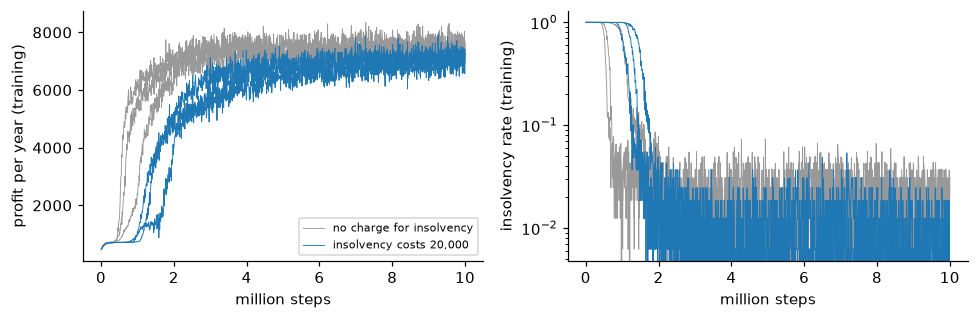

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for cfg, col in (("unpriced", "0.6"), ("lump-20000", "C0")):
    for r in camp.records(cfg):
        steps = np.array([t["steps"] for t in r["monitor"]]) / 1e6
        ax[0].plot(steps, [t["U"] for t in r["monitor"]], color=col, lw=0.6, label=r["note"] if r["seed"] == 1 else None)
        ax[1].plot(steps, [t["failure_rate"] for t in r["monitor"]], color=col, lw=0.6)
ax[0].set_ylabel("profit per year (training)"); ax[1].set_ylabel("insolvency rate (training)"); ax[1].set_yscale("log")
for a in ax: a.set_xlabel("million steps")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
#
# ## 5. The deployed policy and its dispersion
#
# A stochastic policy draws its actions with noise, and the same network without the noise (its mean action) is a
# different candidate. Here the noise is costly: random orders on lines that should not be ordered tie up cash.

In [7]:
noisy = assess(BaseStockRule(retailer, 2.0, 300.0, std=0.1, seed=1))
print(f"rule in use, exact orders:           insolvency {rule_ev['in use (cover 2, reserve 300)'].p_T:6.2%}  profit {rule_ev['in use (cover 2, reserve 300)'].U:7.0f}")
print(f"rule in use, orders with noise 0.1:  insolvency {noisy.p_T:6.2%}  profit {noisy.U:7.0f}")
print()
for cfg in ["lump-5000", "lump-20000"]:
    for s in camp.seeds(cfg):
        sto = camp.evaluation(cfg, s)
        mean = assess(camp.policy(cfg, s, deterministic=True), n=2000, seed=21)
        print(f"{cfg} seed {s}: stochastic policy {sto.p_T:6.2%} / {sto.U:6.0f}    mean action {mean.p_T:6.2%} / {mean.U:6.0f}")

rule in use, exact orders:           insolvency  0.30%  profit    6621
rule in use, orders with noise 0.1:  insolvency  8.55%  profit    6044



lump-5000 seed 1: stochastic policy  1.15% /   7677    mean action  1.00% /   7780


lump-5000 seed 2: stochastic policy  2.80% /   7313    mean action  2.45% /   7334


lump-5000 seed 3: stochastic policy  1.15% /   7547    mean action  1.40% /   7630


lump-20000 seed 1: stochastic policy  0.75% /   7060    mean action  0.85% /   7226


lump-20000 seed 2: stochastic policy  0.85% /   7232    mean action  0.40% /   7268


lump-20000 seed 3: stochastic policy  0.25% /   6943    mean action  0.50% /   7050


The rule loses much of its safety when its orders carry noise. The mean action of a learned policy earns more than
the stochastic policy it comes from in every case here, and is about as risky: sometimes safer, sometimes not, within
the measurement error. If you deploy the mean action, validate the mean action: it is the candidate you deploy.

## 6. Starting from the rule: the prior and the anchor

A learner can start from the rule in use. The campaign fits the network to the rule's orders, gives it a small
dispersion (0.03), and trains from there, either freely or with a parameter anchor that pulls the weights back
toward the fitted ones. The network at the fitted weights is the **prior policy**: the policy one accepts if
training gains nothing. Two practical points come first.

* The fit has to cover the states where the rule's safeguards act. Fitted only on the states the rule itself visits,
  where cash is rarely low, the network misses the cash check and goes insolvent far more often than the rule. The
  campaign fits on the states a noisy version of the rule visits, which include low cash.
* The prior policy is a candidate of its own, and it should be evaluated before training, since the learner inherits
  its risk.

In [8]:
starts = ["prior-only", "anchor-1", "anchor-10"]
print("Prior policies (the fitted network before training):")
print(Campaign.show(camp.table(["prior-only"], which="start_evaluation")))
print("\nAfter training at a cost of 5,000:")
print(Campaign.show(camp.table(["lump-5000"] + starts)))
for cfg in ["anchor-1", "anchor-10"]:
    print(f"{cfg}: weight distance from the prior at the end {np.round([r['anchor_distance'] for r in camp.records(cfg)], 3)}")

Prior policies (the fitted network before training):
configuration    seeds        failure (min-max)          utility (min-max)
prior-only           3     1.133% (0.60%-1.60%)           6494 (6344-6584)

After training at a cost of 5,000:
configuration    seeds        failure (min-max)          utility (min-max)
lump-5000            3     1.700% (1.15%-2.80%)           7512 (7313-7677)
prior-only           3     2.017% (1.00%-2.65%)           6592 (6418-6738)
anchor-1             3     1.000% (0.95%-1.10%)           6527 (6507-6566)
anchor-10            3     1.250% (1.10%-1.45%)           6460 (6398-6535)
anchor-1: weight distance from the prior at the end [0.016 0.013 0.014]
anchor-10: weight distance from the prior at the end [0.003 0.004 0.005]


The prior policy is close to the rule but riskier: the network smooths the rule's cash check. Trained from it, the
learner stays near it. The anchor holds it there, and its risk then varies less from seed to seed; without an anchor
the prior's small dispersion leaves little room to explore, and the learner moves only a little. This is what
parameter regularization does: it holds the learned policy near the prior policy, and the learner inherits that
policy's risk and profit.

Started from scratch, the learner found clearly more profitable policies (section 4). Starting from a rule is a way
to begin near behavior you accept, not a way to improve on the rule. If the rule is good, compare it with a learner
trained from scratch, and deploy whichever the validation and your trade-off favor.

## 7. A tolerance instead of a cost: the adaptive multiplier

Suppose the owners name no cost, and the lender asks for insolvency below 1%. An adaptive multiplier charges a
penalty at insolvency and raises or lowers it after every batch of training years, toward the level at which the
insolvency rate equals the tolerance. The 20,000 run attains about 1%, so that is the level to expect.

Started from scratch, with a step that moves the penalty by half that level in a batch where every year fails, the
multiplier rose far past the level, because the untrained policy fails in most years for many batches; and with a 1%
tolerance it can come down only slowly, by at most 1% of its step per batch. Started instead from the policy and the
level of the 20,000 run, with a twentieth of that level as its step, the multiplier only has to correct a small
error. The control continues the 20,000 run for as long at that fixed cost.

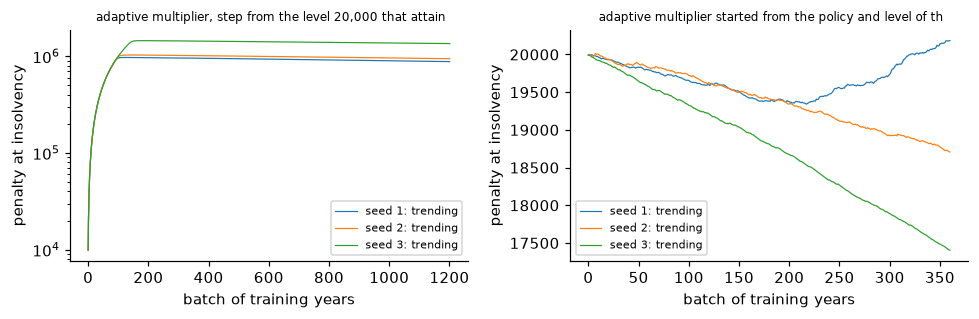

configuration    seeds        failure (min-max)          utility (min-max)
adaptive-1pct        3     0.067% (0.00%-0.10%)           3843 (1370-5940)
adaptive-1pct-warm     3     0.650% (0.10%-1.35%)           7188 (7124-7298)
lump-20000-long      3     0.517% (0.05%-0.80%)           7241 (7185-7336)


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for i, cfg in enumerate(["adaptive-1pct", "adaptive-1pct-warm"]):
    for r in camp.records(cfg):
        nu = [t["multiplier"] for t in r["dual"]["trace"]]
        ax[i].plot(nu, lw=0.8, label=f"seed {r['seed']}: {r['dual']['diagnosis']['status']}")
    ax[i].set_title(camp.records(cfg)[0]["note"].split(":")[1][:60] if camp.records(cfg) else cfg, fontsize=8)
    ax[i].set_xlabel("batch of training years"); ax[i].set_ylabel("penalty at insolvency"); ax[i].legend(fontsize=7)
ax[0].set_yscale("log")
plt.tight_layout(); plt.show()
print(Campaign.show(camp.table(["adaptive-1pct", "adaptive-1pct-warm", "lump-20000-long"])))

From scratch, the multiplier ended near a million and the policies became overly cautious: they almost never go
insolvent and give up much of their profit. Started warm, the multiplier stayed near its level and the policies
match those of the control. For a tolerance, train at a few fixed costs or prices first and pick the one whose runs
meet it; a multiplier, if used, should start from there. `DualAscent.diagnose` reports whether it converged.

## 8. Validate the candidates and report

The candidates inspected are the rule in use, its variants, and the learned policies. We validate the rule in use and
the most profitable learned candidate that met the tolerance on its first evaluation, each on 5,000 fresh years,
with the error shared among the eight candidates.

In [10]:
learned = [(cfg, s) for cfg in costs + starts for s in camp.seeds(cfg)]
best = max(learned, key=lambda cs: camp.evaluation(*cs).U if camp.evaluation(*cs).p_T < req.alpha else -np.inf)
print("most profitable learned candidate under the tolerance:", best)
final = {"the rule in use": assess(rules["in use (cover 2, reserve 300)"].deterministic, n=5000, seed=31),
         f"the learned policy {best[0]}, seed {best[1]}": assess(camp.policy(*best), n=5000, seed=31)}
for name, e in final.items():
    print()
    print(interpret(spec, req, stage, e, candidate_name=name).summary(resource="cash", period="weeks"))

most profitable learned candidate under the tolerance: ('lump-2000', 1)


The rule in use was run on 5000 fresh episodes. It ran out of cash within 52 weeks in 12 of them (0.24%).
With confidence 0.95, its probability of running out within 52 weeks is at most 0.474% (the error 0.05 is shared among 8 candidates).
Requirement (at most 2.00%): met.
Utility per episode: 6602 (standard error 46).
Episodes that came within 5% of running out, or ran out: 0.4%.

What this test does not show:
  - that the policy is the best possible at this risk: how far training fell short of the optimum is not measured;
  - its risk over more than 52 weeks, or that of other policies (its mean action, a retrained network);
  - its behavior outside the simulator.
Every bound with its assumptions: report.text().

The learned policy lump-2000, seed 1 was run on 5000 fresh episodes. It ran out of cash within 52 weeks in 19 of them (0.38%).
With confidence 0.95, its probability of running out within 52 weeks is at most 0.657% (the error 0.05 is shared among 8 candidates).
Requirement (at

Both pass the lender's tolerance; the report states what the test shows and what it does not. Which to deploy is the
firm's choice between profit and risk, and the evidence for either is the same kind. `report.text()` lists every
bound with its assumptions.

## Train it yourself

Each configuration of the campaign is one command; a run takes about six minutes on one CPU core.

```bash
python campaigns/run.py retailer lump-5000 --seed 4
```

The configurations are defined in `campaigns/problems.py`; `bpg/problems/inventory.py` is the simulator, a template
for writing your own problem as a budget.